# ATD tracking: contents, missingness and distributions

This notebook explores both tracking pairs locally:

- `*_atd.xml`: metadata describing teams and track slots.
- `*_atd.txt`: one tracking record per video frame, containing player and ball position/speed observations.

It uses a streaming parser so the full tracking files do not need to be loaded through kloppy. The tactical and broadcast timelines are analysed separately and are never joined.

> Do not commit this notebook with outputs or upload its outputs to hosted AI services.

In [1]:
from pathlib import Path
from collections import Counter
import os
import xml.etree.ElementTree as ET

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

def find_repo_root(start=Path.cwd()):
    for candidate in (start, *start.parents):
        if (candidate / 'games.py').exists() and (candidate / 'DATA.md').exists():
            return candidate
    raise FileNotFoundError('Could not find the repository root')

ROOT = find_repo_root()
DATA_ROOT = Path(os.environ.get('MTAH_DATA_DIR', ROOT / 'data'))
FPS = 25

def locate(source, filename):
    candidates = [DATA_ROOT / source / filename, DATA_ROOT / filename]
    for path in candidates:
        if path.exists():
            return path
    raise FileNotFoundError(f'Could not find {filename} in {candidates}')

## 1. XML metadata

The XML is required to interpret the raw text. In particular, it maps every track slot to its team. Track slots are temporary tracklets, not permanent player identities or shirt numbers.

In [2]:
def local_tag(element):
    return element.tag.rsplit('}', 1)[-1]

def child_text(element, name):
    for child in element:
        if local_tag(child) == name:
            return child.text
    return None

def read_metadata(path):
    root = ET.parse(path).getroot()
    teams = [e for e in root.iter() if local_tag(e) == 'Team']
    players = [e for e in root.iter() if local_tag(e) == 'Player']
    team_rows = []
    for team in teams:
        team_id = team.get('id')
        team_rows.append({
            'team_id': team_id,
            'name': child_text(team, 'Name'),
            'track_slots': sum(p.get('teamId') == team_id for p in players),
        })
    slot_team_ids = [p.get('teamId') for p in players]
    element_counts = Counter(local_tag(e) for e in root.iter())
    return pd.DataFrame(team_rows), slot_team_ids, element_counts

metadata = {}
for source in ('tactical', 'broadcast'):
    xml_path = locate(source, f'BAR-ATH_{source}_atd.xml')
    teams, slot_team_ids, element_counts = read_metadata(xml_path)
    metadata[source] = {
        'teams': teams,
        'slot_team_ids': slot_team_ids,
        'home_id': teams.iloc[0]['team_id'] if len(teams) else None,
    }
    print(f'\n{source.upper()} XML: {xml_path.name}')
    display(teams)
    print('Track slots:', len(slot_team_ids))
    print('Most common XML elements:', element_counts.most_common(8))


TACTICAL XML: BAR-ATH_tactical_atd.xml


,team_id,name,track_slots
0,MET_user_team_o4Hossvb8M,Barcelona,24
1,MET_user_team_x7C4FFX2HF,Atletic Club,22


Track slots: 46
Most common XML elements: [('Name', 252), ('ProviderParameter', 198), ('Value', 198), ('PlayerChannel', 138), ('PlayerChannelRef', 138), ('SplitRegister', 48), ('Player', 46), ('ShirtNumber', 46)]

BROADCAST XML: BAR-ATH_broadcast_atd.xml


,team_id,name,track_slots
0,MET_user_team_o4Hossvb8M,Barcelona,26
1,MET_user_team_x7C4FFX2HF,Atletic Club,25


Track slots: 51
Most common XML elements: [('Name', 277), ('ProviderParameter', 218), ('Value', 218), ('PlayerChannel', 153), ('PlayerChannelRef', 153), ('SplitRegister', 53), ('Player', 51), ('ShirtNumber', 51)]


## 2. Raw per-frame tracking

Each raw record has three sections: frame ID, semicolon-separated player tracklets, and the ball. Every observation is `x,y,speed`; missing observations are `NaN`. Positions are normalised to approximately 0–1 pitch coordinates.

The parser below produces one compact summary row per frame and samples player positions once per second for distribution plots. Reading both complete files may take a few minutes.

In [3]:
def parse_observation(text):
    text = text.strip()
    if not text or text[0].upper() == 'N':
        return np.nan, np.nan, np.nan
    values = text.split(',')
    if len(values) < 3:
        return np.nan, np.nan, np.nan
    return float(values[0]), float(values[1]), float(values[2])

def stream_tracking(path, slot_team_ids, home_id, sample_every=25):
    rows = []
    sampled_positions = []

    with path.open('r') as handle:
        for record_number, line in enumerate(handle):
            parts = line.rstrip().split(':')
            if len(parts) != 3:
                continue
            frame_id = int(parts[0])
            player_groups = parts[1].split(';')
            ball_x, ball_y, ball_speed = parse_observation(parts[2])

            visible = home_visible = away_visible = 0
            sample_this_frame = record_number % sample_every == 0
            for slot, group in enumerate(player_groups):
                x, y, speed = parse_observation(group)
                if np.isnan(x) or np.isnan(y):
                    continue
                visible += 1
                team_id = slot_team_ids[slot] if slot < len(slot_team_ids) else None
                side = 'home' if team_id == home_id else 'away'
                home_visible += side == 'home'
                away_visible += side == 'away'
                if sample_this_frame:
                    sampled_positions.append({
                        'frame_id': frame_id, 'side': side, 'x': x, 'y': y, 'speed': speed
                    })

            rows.append({
                'frame_id': frame_id,
                'ball_present': not (np.isnan(ball_x) or np.isnan(ball_y)),
                'ball_x': ball_x, 'ball_y': ball_y, 'ball_speed': ball_speed,
                'players_visible': visible,
                'home_visible': home_visible,
                'away_visible': away_visible,
            })

    return pd.DataFrame(rows), pd.DataFrame(sampled_positions)

In [4]:
summaries = {}
position_samples = {}

for source in ('tactical', 'broadcast'):
    raw_path = locate(source, f'BAR-ATH_{source}_atd.txt')
    print(f'Reading {raw_path.name} ...')
    summary, positions = stream_tracking(
        raw_path, metadata[source]['slot_team_ids'], metadata[source]['home_id'],
        sample_every=FPS
    )
    summary['source'] = source
    summaries[source] = summary
    position_samples[source] = positions
    print(f'  {len(summary):,} frame records; {len(positions):,} sampled player observations')

Reading BAR-ATH_tactical_atd.txt ...
  199,319 frame records; 151,353 sampled player observations
Reading BAR-ATH_broadcast_atd.txt ...
  164,488 frame records; 75,459 sampled player observations


## 3. What one derived frame table looks like

This is a compact view derived from the raw file. It is a useful starting point for Person 1's feature matrix.

In [5]:
display(summaries['tactical'].head(10))
display(summaries['tactical'].describe(include='all').T)

,frame_id,ball_present,ball_x,ball_y,ball_speed,players_visible,home_visible,away_visible,source
0,1,False,NaN,NaN,NaN,7,2,5,tactical
1,2,False,NaN,NaN,NaN,8,2,6,tactical
2,3,False,NaN,NaN,NaN,8,2,6,tactical
3,4,False,NaN,NaN,NaN,8,2,6,tactical
4,5,False,NaN,NaN,NaN,8,2,6,tactical
5,6,False,NaN,NaN,NaN,8,2,6,tactical
6,7,False,NaN,NaN,NaN,8,2,6,tactical
7,8,False,NaN,NaN,NaN,8,2,6,tactical
8,9,False,NaN,NaN,NaN,8,2,6,tactical
9,10,False,NaN,NaN,NaN,8,2,6,tactical


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
frame_id,199319.0,NaN,NaN,NaN,99660.0,57538.58349,1.0,49830.5,99660.0,149489.5,199319.0
ball_present,199319,2,True,113488,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ball_x,113488.0,NaN,NaN,NaN,0.502648,0.239323,-0.06517,0.318747,0.529655,0.67523,1.11385
ball_y,113488.0,NaN,NaN,NaN,0.57056,0.284386,-0.10713,0.356928,0.585035,0.80456,1.48854
ball_speed,9909.0,NaN,NaN,NaN,1.517047,1.226468,0.002036,0.696324,1.208879,1.770334,7.271594
players_visible,199319.0,NaN,NaN,NaN,18.976721,5.125796,1.0,18.0,21.0,22.0,35.0
home_visible,199319.0,NaN,NaN,NaN,9.659571,2.990453,0.0,10.0,11.0,11.0,24.0
away_visible,199319.0,NaN,NaN,NaN,9.31715,2.809199,0.0,9.0,11.0,11.0,15.0
source,199319,1,tactical,199319,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
integrity_rows = []
for source, df in summaries.items():
    ids = df['frame_id'].to_numpy()
    integrity_rows.append({
        'source': source,
        'records': len(df),
        'first_frame_id': int(ids[0]),
        'last_frame_id': int(ids[-1]),
        'contiguous': bool(np.all(np.diff(ids) == 1)),
        'ball_present_pct': round(100 * df['ball_present'].mean(), 2),
        'mean_players_visible': round(df['players_visible'].mean(), 2),
    })
display(pd.DataFrame(integrity_rows))

,source,records,first_frame_id,last_frame_id,contiguous,ball_present_pct,mean_players_visible
0,tactical,199319,1,199319,True,56.94,18.98
1,broadcast,164488,1,164488,True,50.53,11.48


## 4. Missingness and visibility distributions

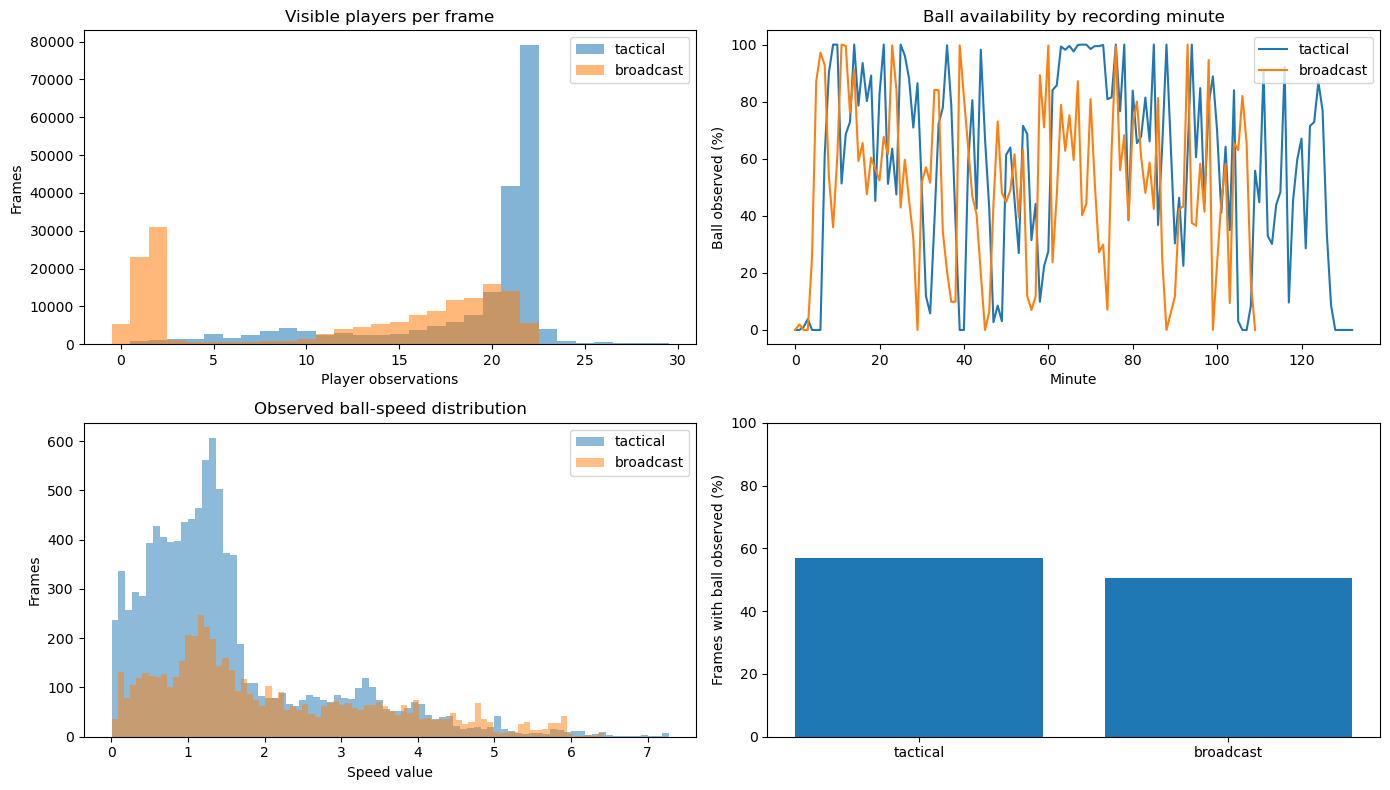

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for source, df in summaries.items():
    axes[0, 0].hist(df['players_visible'], bins=np.arange(0, 31) - 0.5, alpha=0.55, label=source)
    minute = ((df['frame_id'] - 1) // (FPS * 60)).astype(int)
    availability = df.groupby(minute)['ball_present'].mean() * 100
    axes[0, 1].plot(availability.index, availability.values, label=source)
    axes[1, 0].hist(df.loc[df['ball_present'], 'ball_speed'].dropna(), bins=80, alpha=0.5, label=source)

availability_pct = pd.Series({s: 100 * d['ball_present'].mean() for s, d in summaries.items()})
axes[1, 1].bar(availability_pct.index, availability_pct.values)
axes[1, 1].set_ylim(0, 100)
axes[1, 1].set_ylabel('Frames with ball observed (%)')

axes[0, 0].set(title='Visible players per frame', xlabel='Player observations', ylabel='Frames')
axes[0, 1].set(title='Ball availability by recording minute', xlabel='Minute', ylabel='Ball observed (%)')
axes[1, 0].set(title='Observed ball-speed distribution', xlabel='Speed value', ylabel='Frames')
for ax in axes.flat[:3]:
    ax.legend()
fig.tight_layout()
plt.show()

## 5. Spatial distributions

These plots use sampled observations. They reveal coordinate coverage and obvious outliers without requiring either MP4.

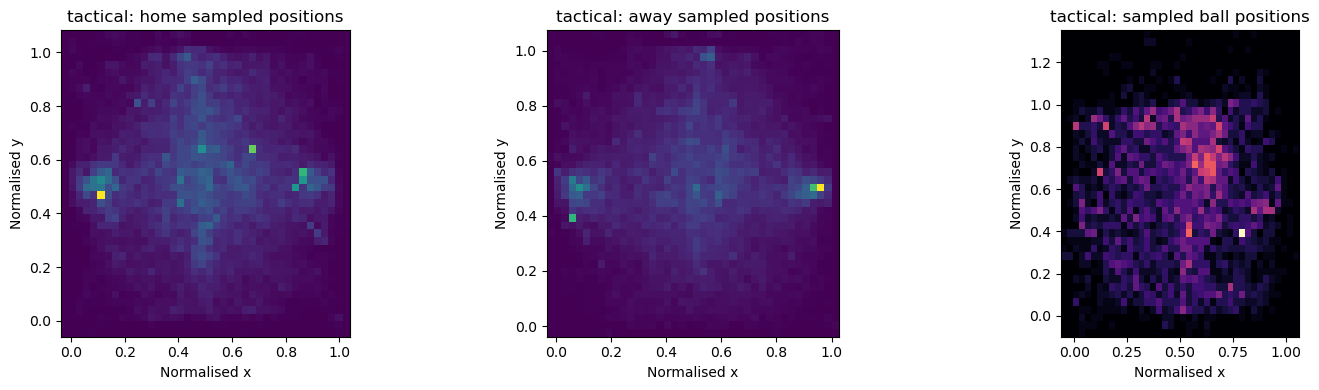

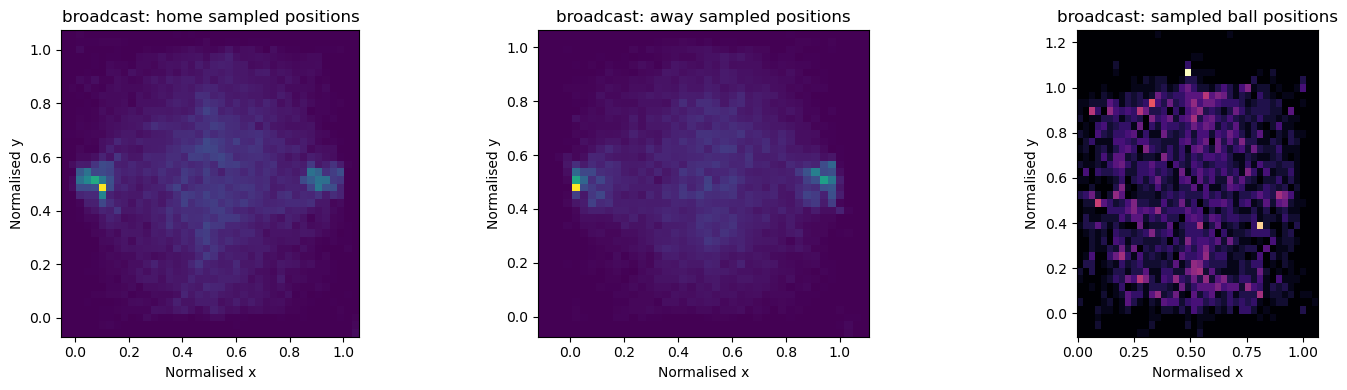

In [8]:
for source in ('tactical', 'broadcast'):
    df = summaries[source]
    positions = position_samples[source]
    ball = df.loc[df['ball_present'], ['ball_x', 'ball_y']].iloc[::FPS]

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, side in zip(axes[:2], ('home', 'away')):
        points = positions[positions['side'] == side]
        ax.hist2d(points['x'], points['y'], bins=40, cmap='viridis')
        ax.set(title=f'{source}: {side} sampled positions', xlabel='Normalised x', ylabel='Normalised y')
        ax.set_aspect('equal')
    axes[2].hist2d(ball['ball_x'], ball['ball_y'], bins=40, cmap='magma')
    axes[2].set(title=f'{source}: sampled ball positions', xlabel='Normalised x', ylabel='Normalised y')
    axes[2].set_aspect('equal')
    fig.tight_layout()
    plt.show()

## What Person 1 should take from this

Good first features include ball visibility/speed, visible-player counts, nearest home/away distance to the ball, counts near the ball, and explicit missingness masks. Avoid using track-slot number as player identity.

Use tactical data for the submission timeline. Broadcast data is optional and requires a separate alignment method before it can contribute to tactical-frame predictions.

---

**Before committing:** restart the kernel, clear every output, and save.